In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("spotify_user_behavior.csv")

In [5]:
df.head()

,user_id,country,age,signup_date,subscription_type,subscription_status,months_inactive,inactive_3_months_flag,ad_interaction,ad_conversion_to_subscription,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,favorite_genre,most_liked_feature,desired_future_feature,primary_device,playlists_created,avg_skips_per_day
0,1,France,25,2021-08-19,Premium Duo,Active,0,0,No,No,4,10.13,Bollywood,Radio,Concert Alerts,Tablet,7,8
1,2,Indonesia,20,2022-06-06,Premium Family,Active,0,0,Yes,No,5,11.63,Latin,Podcasts,Lyrics Translation,Mobile,7,6
2,3,Italy,53,2024-01-04,Premium Individual,Active,0,0,Yes,Yes,3,9.50,Bollywood,Lyrics,Better AI Recommendations,Desktop,6,5
3,4,Italy,48,2018-08-26,Premium Individual,Active,1,0,No,No,4,13.16,Electronic,Playlists,Social Listening,Smart Speaker,11,8
4,5,Australia,18,2020-05-29,Free,Active,0,0,No,No,4,12.70,Indie,Daily Mix,Lyrics Translation,Tablet,10,11


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   user_id                         50000 non-null  int64  
 1   country                         50000 non-null  object 
 2   age                             50000 non-null  int64  
 3   signup_date                     50000 non-null  object 
 4   subscription_type               50000 non-null  object 
 5   subscription_status             50000 non-null  object 
 6   months_inactive                 50000 non-null  int64  
 7   inactive_3_months_flag          50000 non-null  int64  
 8   ad_interaction                  50000 non-null  object 
 9   ad_conversion_to_subscription   50000 non-null  object 
 10  music_suggestion_rating_1_to_5  50000 non-null  int64  
 11  avg_listening_hours_per_week    50000 non-null  float64
 12  favorite_genre                  

In [8]:
df.columns

Index(['user_id', 'country', 'age', 'signup_date', 'subscription_type',
       'subscription_status', 'months_inactive', 'inactive_3_months_flag',
       'ad_interaction', 'ad_conversion_to_subscription',
       'music_suggestion_rating_1_to_5', 'avg_listening_hours_per_week',
       'favorite_genre', 'most_liked_feature', 'desired_future_feature',
       'primary_device', 'playlists_created', 'avg_skips_per_day'],
      dtype='object')

In [12]:
print(df['subscription_status'].value_counts())
print("\n--- Compare with 3 months inactive ---")
print(pd.crosstab(df['subscription_status'], df['inactive_3_months_flag']))

subscription_status
Active      42109
Inactive     7891
Name: count, dtype: int64

--- Compare with 3 months inactive ---
inactive_3_months_flag      0     1
subscription_status                
Active                  38877  3232
Inactive                    0  7891


<Axes: xlabel='subscription_status', ylabel='avg_listening_hours_per_week'>

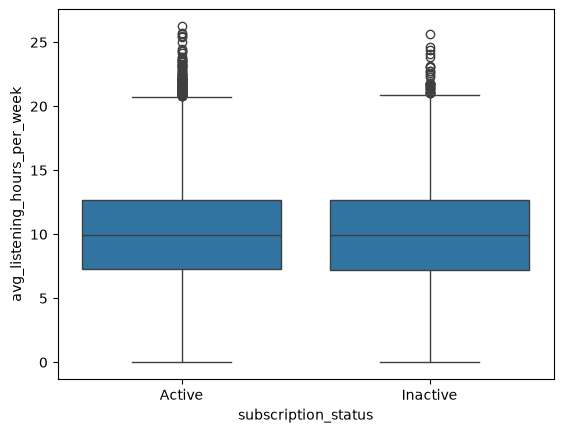

In [14]:
sns.boxplot(data = df, x="subscription_status", y="avg_listening_hours_per_week")

<Axes: xlabel='music_suggestion_rating_1_to_5', ylabel='count'>

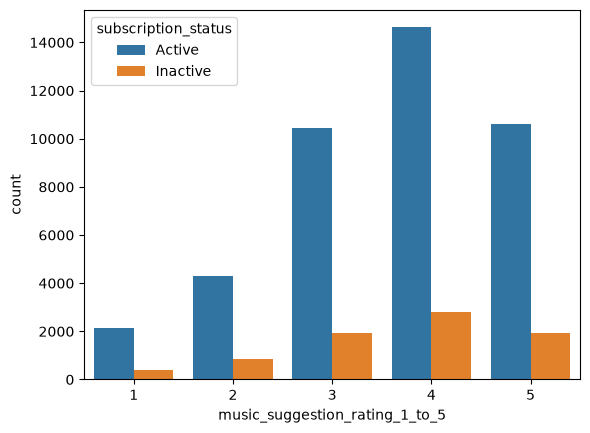

In [15]:
sns.countplot(data = df, x="music_suggestion_rating_1_to_5",hue="subscription_status")

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Premium Duo'),
  Text(1, 0, 'Premium Family'),
  Text(2, 0, 'Premium Individual'),
  Text(3, 0, 'Free'),
  Text(4, 0, 'Student')])

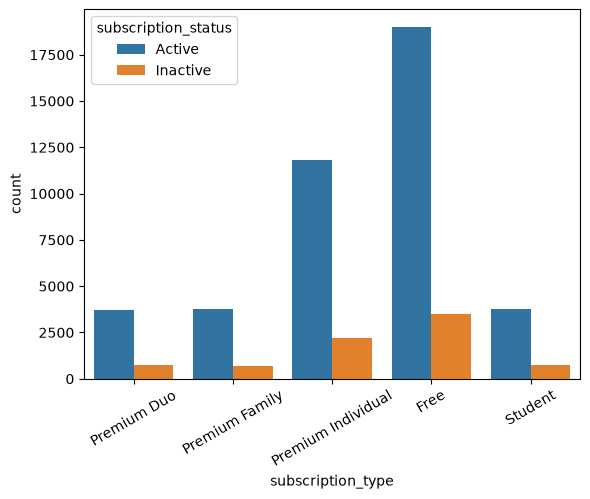

In [23]:
sns.countplot(data=df, x="subscription_type", hue="subscription_status")
plt.xticks(rotation=30)

In [24]:
df.isnull().sum()

user_id                           0
country                           0
age                               0
signup_date                       0
subscription_type                 0
subscription_status               0
months_inactive                   0
inactive_3_months_flag            0
ad_interaction                    0
ad_conversion_to_subscription     0
music_suggestion_rating_1_to_5    0
avg_listening_hours_per_week      0
favorite_genre                    0
most_liked_feature                0
desired_future_feature            0
primary_device                    0
playlists_created                 0
avg_skips_per_day                 0
dtype: int64

In [30]:
X = df.drop(columns = ["user_id","signup_date","subscription_status","months_inactive","inactive_3_months_flag",], axis = 1)
y = (df["subscription_status"] == "Inactive").astype(int)

In [33]:
y

0        0
1        0
2        0
3        0
4        0
        ..
49995    0
49996    0
49997    0
49998    0
49999    1
Name: subscription_status, Length: 50000, dtype: int64

In [38]:
X_encode = pd.get_dummies(X, drop_first = True)

In [39]:
X_encode.astype(int)

,age,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,country_Brazil,country_Canada,country_France,country_Germany,country_India,...,most_liked_feature_Radio,desired_future_feature_Concert Alerts,desired_future_feature_HiFi Audio,desired_future_feature_Lyrics Translation,desired_future_feature_Mood-based Auto Playlists,desired_future_feature_Social Listening,primary_device_Desktop,primary_device_Mobile,primary_device_Smart Speaker,primary_device_Tablet
0,25,4,10,7,8,0,0,1,0,0,...,1,1,0,0,0,0,0,0,0,1
1,20,5,11,7,6,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
2,53,3,9,6,5,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,48,4,13,11,8,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,18,4,12,10,11,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,33,5,11,8,5,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
49996,35,4,8,11,10,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
49997,33,2,14,9,13,1,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
49998,43,5,21,9,12,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X_encode, y, test_size=0.2, random_state=42, stratify=y)

In [42]:
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [43]:
y_pred = model.predict(X_test)

In [44]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      1.00      0.91      8422
           1       0.25      0.01      0.01      1578

    accuracy                           0.84     10000
   macro avg       0.55      0.50      0.46     10000
weighted avg       0.75      0.84      0.77     10000



In [45]:
print("Top 5 Reasons Users Churn:")
print(pd.Series(model.feature_importances_, index=X_encode.columns).nlargest(5))

Top 5 Reasons Users Churn:
avg_listening_hours_per_week      0.140624
age                               0.116786
avg_skips_per_day                 0.092251
playlists_created                 0.087071
music_suggestion_rating_1_to_5    0.048678
dtype: float64


## Customer Churn Analysis — Final Summary

### 1. Churn Definition & Data Leakage Prevention
- **Target (`y`):** Defined churn as `subscription_status == "Inactive"` (`1` = Inactive/Churned, `0` = Active) across the `spotify_user_behavior.csv` dataset.
- **Leakage Removal:** Excluded direct inactivity/target columns (`months_inactive`, `inactive_3_months_flag`, `subscription_status`) as well as identifiers/dates (`user_id`, `signup_date`) from model features (`X`) so the model learns genuine behavioral patterns rather than relying on post-churn or direct inactivity flags.

### 2. Model Performance & Why Accuracy Alone Is Misleading
- On the test set (`10,000` users: `8,422` active and `1,578` inactive), the `RandomForestClassifier` achieved **0.84 accuracy**, but **recall for churners (`1`) was `0.01`** (precision `0.25`, F1-score `0.01`).
- Because ~84% of users are active, overall accuracy is inflated by majority-class predictions and misses nearly all actual churners. Evaluation must therefore prioritize recall/precision on the churned class and threshold/feature tuning rather than raw accuracy alone.

### 3. Top 5 Drivers of Churn (Feature Importance)
1. **`avg_listening_hours_per_week`** (`0.1406`) — Weekly listening engagement level
2. **`age`** (`0.1168`) — User age demographic
3. **`avg_skips_per_day`** (`0.0923`) — Daily track-skipping friction/dissatisfaction
4. **`playlists_created`** (`0.0871`) — Active playlist curation/investment in the platform
5. **`music_suggestion_rating_1_to_5`** (`0.0487`) — Perceived quality of music recommendations

### 4. Actionable Retention Recommendations
- **Target Low-Listening & High-Skip Users Early:** Trigger personalized playlists, genre refresh prompts, or targeted nudges when a user's weekly listening drops or daily skips spike—before they slip into long-term inactivity.
- **Encourage Playlist Creation:** Prompt new or low-engagement users to build playlists early to increase switching costs and habitual usage.
- **Improve Recommendation Relevance:** Use low suggestion ratings (`1–2`) to tune discovery feeds and re-engage dissatisfied listeners.